In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.9/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.9/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
from pyCRLD.Environments.TwoArmedBandit import TwoArmedBandit
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Agents.StrategySARSA import stratSARSA
from pyCRLD.Utils.PhasePlot import phaseplot, _data_to_plot, _strategies, _dXisa_s
import numpy as np

In [ ]:
from qBaseDistR import qbaseDist
from qBaseSARSA import qbaseSARSA

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl

In [ ]:
# Poor environment
env = TwoArmedBandit(rew=1, pun=-1, pA=0.3, pB=0.1)

In [ ]:
b_pes = np.linspace(0.1, 1., 10)
b_opt = np.linspace(1., 10., 10)
b_ratios = np.zeros((19))
b_ratios[:9] = b_pes[:9]
b_ratios[9:] = b_opt

In [ ]:
b_ratios

array([ 0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ,  2. ,
        3. ,  4. ,  5. ,  6. ,  7. ,  8. ,  9. , 10. ])

In [ ]:
w_pes = np.linspace(0.1, 1., 10)
w_opt = np.linspace(1., 10., 10)
w_ratios = np.zeros((19))
w_ratios[:9] = w_pes[:9]
w_ratios[9:] = w_opt
# w_ratios = w_ratios[::4]

In [ ]:
w_ratios

array([ 0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ,  2. ,
        3. ,  4. ,  5. ,  6. ,  7. ,  8. ,  9. , 10. ])

In [ ]:
def deltaQinf(p0, p1, x):
    return ((p0 * x - (1 - p0)) / (p0 * x + (1 - p0))) - ((p1 * x - (1 - p1)) / (p1 * x + (1 - p1)))

In [ ]:
def Xinf(dQ, beta):
    return 1 / (1 + np.exp(beta * (-dQ)))

In [ ]:
w_xinf = np.zeros((len(w_ratios)))

In [ ]:
b_dQs = deltaQinf(0.3, 0.1, b_ratios)
b_xinf = Xinf(b_dQs, 4)

In [ ]:
for i, w in enumerate(w_ratios):
    mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                     learning_rates=0.1, discount_factors=0,
                     choice_intensities=4, Rmin=-1, Rmax=1,
                     method='weights', wU=w, use_prefactor=False)
    X = 0.5 * np.ones((1, 3, 2))
    traj, fpreached = mae.trajectory(X, 150)
    w_xinf[i] = traj[-1, 0, 0, 0]
    print('done')

done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done


Text(0, 0.5, 'final $X_{00}$')

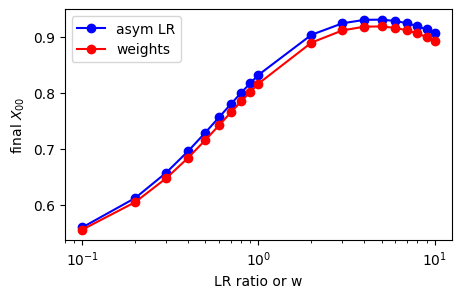

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax.set_xscale('log')
ax.plot(b_ratios, b_xinf, '-o', color='blue', label="asym LR")
ax.plot(w_ratios, w_xinf, '-o', color='red', label="weights")
ax.legend(loc='upper left')
ax.set_xlabel("LR ratio or w")
ax.set_ylabel("final "+r'$X_{00}$')

In [ ]:
from pyCRLD.Utils.Trajectories1D import trajectories_1D 

In [ ]:
x = ([0], [0, 1, 2], [0])
res = np.linspace(0, 1., 5)

In [ ]:
mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                 learning_rates=0.1, discount_factors=0,
                 choice_intensities=4, Rmin=-1, Rmax=1,
                 method='weights', wU=1., use_prefactor=False)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


array([<Axes: title={'center': 'state 0'}, xlabel='step', ylabel='prob. act. 0'>,
       <Axes: title={'center': 'state 1'}, xlabel='step'>,
       <Axes: title={'center': 'state 2'}, xlabel='step'>], dtype=object)

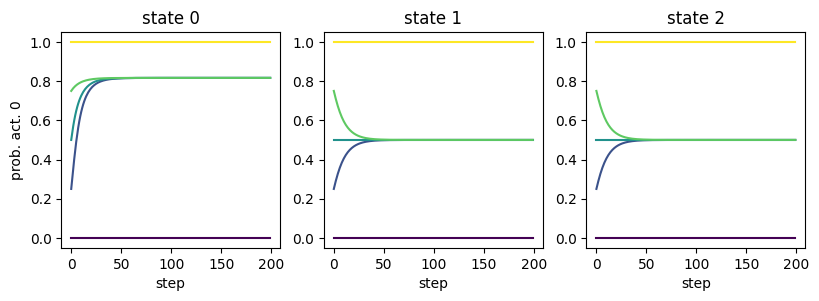

In [ ]:
trajectories_1D(mae, x, res, NrRandom=1, traj_len=200)

In [ ]:
mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                 learning_rates=0.1, discount_factors=0,
                 choice_intensities=4, Rmin=-1, Rmax=1,
                 method='weights', wU=2., use_prefactor=False)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


array([<Axes: title={'center': 'state 0'}, xlabel='step', ylabel='prob. act. 0'>,
       <Axes: title={'center': 'state 1'}, xlabel='step'>,
       <Axes: title={'center': 'state 2'}, xlabel='step'>], dtype=object)

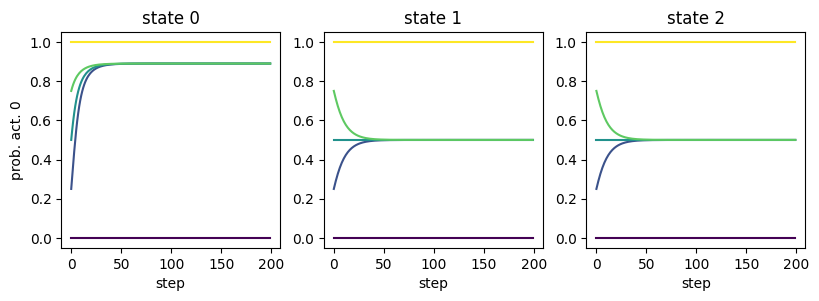

In [ ]:
trajectories_1D(mae, x, res, NrRandom=1, traj_len=200)

## 1-state two-armed bandit

In [ ]:
from pyCRLD.Environments.DistTwoArmedBanditOneState import DistTwoArmedBanditOneState

In [ ]:
# Poor env
xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.7, 0.3],
               [0.9, 0.1]])
env = DistTwoArmedBanditOneState(disttype='discrete', xs=xs, ps=ps)

In [ ]:
mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                 learning_rates=0.1, discount_factors=0,
                 choice_intensities=4, Rmin=-1, Rmax=1,
                 method='weights', wU=1., use_prefactor=False)

In [ ]:
x = ([0], [0], [0])
res = np.linspace(0, 1., 5)

[<Axes: title={'center': 'state 0'}, xlabel='step', ylabel='prob. act. 0'>]

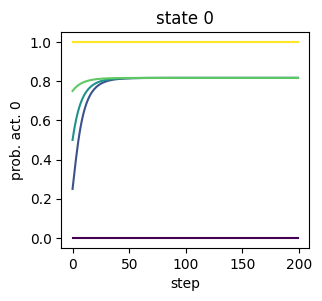

In [ ]:
trajectories_1D(mae, x, res, NrRandom=1, traj_len=200)

In [ ]:
mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                 learning_rates=0.1, discount_factors=0,
                 choice_intensities=4, Rmin=-1, Rmax=1,
                 method='weights', wU=2., use_prefactor=False)

[<Axes: title={'center': 'state 0'}, xlabel='step', ylabel='prob. act. 0'>]

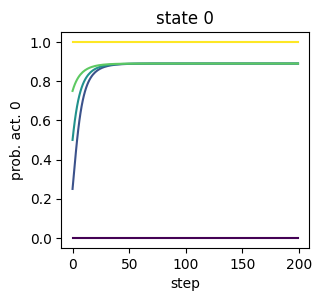

In [ ]:
trajectories_1D(mae, x, res, NrRandom=1, traj_len=200)

In [ ]:
b_pes = np.linspace(0.1, 1., 10)
b_opt = np.linspace(1., 10., 10)
b_ratios = np.zeros((19))
b_ratios[:9] = b_pes[:9]
b_ratios[9:] = b_opt

In [ ]:
w_pes = np.linspace(0.1, 1., 10)
w_opt = np.linspace(1., 10., 10)
w_ratios = np.zeros((19))
w_ratios[:9] = w_pes[:9]
w_ratios[9:] = w_opt
# w_ratios = w_ratios[::4]

In [ ]:
w_xinf = np.zeros((len(w_ratios)))

In [ ]:
b_dQs = deltaQinf(0.3, 0.1, b_ratios)
b_xinf = Xinf(b_dQs, 4)

In [ ]:
for i, w in enumerate(w_ratios):
    mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                     learning_rates=0.1, discount_factors=0,
                     choice_intensities=4, Rmin=-1, Rmax=1,
                     method='weights', wU=w, use_prefactor=False)
    X = 0.5 * np.ones((1, 1, 2))
    traj, fpreached = mae.trajectory(X, 150)
    w_xinf[i] = traj[-1, 0, 0, 0]
    print('done')

done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done


Text(0, 0.5, 'final $X_{00}$')

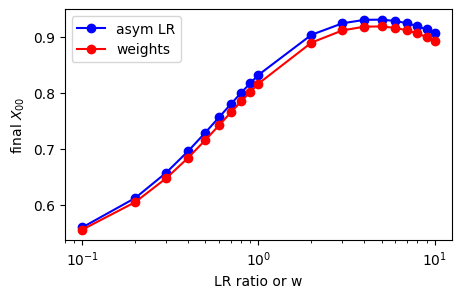

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax.set_xscale('log')
ax.plot(b_ratios, b_xinf, '-o', color='blue', label="asym LR")
ax.plot(w_ratios, w_xinf, '-o', color='red', label="weights")
ax.legend(loc='upper left')
ax.set_xlabel("LR ratio or w")
ax.set_ylabel("final "+r'$X_{00}$')